## 1. Data Loading & Initial Inspection

In [1]:
import os
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

Load via kagglehub download path

In [2]:
import kagglehub

path = kagglehub.dataset_download("ruchi798/data-science-job-salaries")
print("Path to dataset files:", path)   
print("Files:", os.listdir(path))

Path to dataset files: C:\Users\anton\.cache\kagglehub\datasets\ruchi798\data-science-job-salaries\versions\1
Files: ['ds_salaries.csv']


In [3]:
csv_files = [f for f in os.listdir(path) if f.lower().endswith(".csv")]
if not csv_files:
    raise FileNotFoundError("No CSV file found in the downloaded dataset folder.")
csv_path = os.path.join(path, csv_files[0])

df = pd.read_csv(csv_path)

# Mandatory Step 1 checks

In [4]:
print("Shape (rows, cols):", df.shape)

display(df.head(5))

Shape (rows, cols): (607, 12)


,Unnamed: 0,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,0,DE,L
1,1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,0,JP,S
2,2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,50,GB,M
3,3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,0,HN,S
4,4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,50,US,L


In [5]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['Unnamed: 0', 'work_year', 'experience_level', 'employment_type', 'job_title', 'salary', 'salary_currency', 'salary_in_usd', 'employee_residence', 'remote_ratio', 'company_location', 'company_size']


In [6]:
print("\nInfo:")
df.info()


Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 607 entries, 0 to 606
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Unnamed: 0          607 non-null    int64 
 1   work_year           607 non-null    int64 
 2   experience_level    607 non-null    object
 3   employment_type     607 non-null    object
 4   job_title           607 non-null    object
 5   salary              607 non-null    int64 
 6   salary_currency     607 non-null    object
 7   salary_in_usd       607 non-null    int64 
 8   employee_residence  607 non-null    object
 9   remote_ratio        607 non-null    int64 
 10  company_location    607 non-null    object
 11  company_size        607 non-null    object
dtypes: int64(5), object(7)
memory usage: 57.0+ KB


In [7]:
print("\nDescribe (numeric + categorical):")
display(df.describe(include="all").T)


Describe (numeric + categorical):


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,607.0,NaN,NaN,NaN,303.0,175.370085,0.0,151.5,303.0,454.5,606.0
work_year,607.0,NaN,NaN,NaN,2021.405272,0.692133,2020.0,2021.0,2022.0,2022.0,2022.0
experience_level,607,4,SE,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_type,607,4,FT,588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_title,607,50,Data Scientist,143,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary,607.0,NaN,NaN,NaN,324000.062603,1544357.486636,4000.0,70000.0,115000.0,165000.0,30400000.0
salary_currency,607,17,USD,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary_in_usd,607.0,NaN,NaN,NaN,112297.869852,70957.259411,2859.0,62726.0,101570.0,150000.0,600000.0
employee_residence,607,57,US,332,NaN,NaN,NaN,NaN,NaN,NaN,NaN
remote_ratio,607.0,NaN,NaN,NaN,70.92257,40.70913,0.0,50.0,100.0,100.0,100.0


In [8]:
print("\nDtypes:")
print(df.dtypes)


Dtypes:
Unnamed: 0             int64
work_year              int64
experience_level      object
employment_type       object
job_title             object
salary                 int64
salary_currency       object
salary_in_usd          int64
employee_residence    object
remote_ratio           int64
company_location      object
company_size          object
dtype: object


## 2. Data Understanding & Data Quality Checks

### 2.1 Objective of This Step

In this step, we assess the overall quality and structure of the dataset. This includes checking for missing values, duplicate records, and potential inconsistencies across features. No transformations are applied at this stage. The goal is to identify any data quality issues that need to be addressed before proceeding to data cleaning and modeling.

### 2.2 Missing Values Analysis

- No missing values were found in any of the columns.
- All features have complete records across the dataset.
- From a missing-data perspective, the dataset is ready for further analysis and modeling.

In [9]:
df.isnull().sum()

Unnamed: 0            0
work_year             0
experience_level      0
employment_type       0
job_title             0
salary                0
salary_currency       0
salary_in_usd         0
employee_residence    0
remote_ratio          0
company_location      0
company_size          0
dtype: int64

### 2.3 Duplicate Records Check

- No duplicate rows were detected in the dataset.
- Each observation in the dataset appears to be unique.
- Duplicate records are not a concern for further analysis or modeling.

In [10]:
df.duplicated().sum()

np.int64(0)

### 2.4 Feature-Level Understanding

- **work_year**: The year in which the employee’s salary information was recorded.
- **experience_level**: Categorical feature representing the employee’s level of experience, encoded using abbreviated labels (e.g., EN, MI, SE, EX).
- **employment_type**: Categorical feature indicating the type of employment, represented by abbreviated codes (e.g., FT, PT, CT, FL).
- **job_title**: The job role or position held by the employee.
- **salary**: The reported salary amount in the original currency.
- **salary_currency**: The currency in which the salary is paid.
- **salary_in_usd**: The salary converted to USD.
- **employee_residence**: The country of residence of the employee.
- **remote_ratio**: The proportion of work performed remotely, expressed as a percentage.
- **company_location**: The country where the employing company is located.
- **company_size**: Categorical feature indicating the size of the company based on number of employees.


### 2.5 Numerical Feature Ranges

In [11]:
numerical_features = ['work_year','salary','salary_in_usd','remote_ratio']

summary_stats = df[numerical_features].describe().T
summary_stats

,count,mean,std,min,25%,50%,75%,max
work_year,607.0,2021.405272,6.921330e-01,2020.0,2021.0,2022.0,2022.0,2022.0
salary,607.0,324000.062603,1.544357e+06,4000.0,70000.0,115000.0,165000.0,30400000.0
salary_in_usd,607.0,112297.869852,7.095726e+04,2859.0,62726.0,101570.0,150000.0,600000.0
remote_ratio,607.0,70.922570,4.070913e+01,0.0,50.0,100.0,100.0,100.0


## 3. Data Cleaning & Preprocessing

### 3.1 Cleaning Strategy and Objectives
- Remove non-informative or index-like columns that do not contribute to analysis or modeling.
- Select the most appropriate salary-related feature for modeling and analysis.
- Standardize categorical features by preparing them for encoding in later steps.
- Ensure numerical features are in appropriate formats and ready for analysis.
- Preserve data integrity by applying minimal and well-justified transformations.
- Prepare the dataset for exploratory data analysis and predictive modeling.


### 3.2 Column Removal and Target Selection

#### Column Removal
- The column `Unnamed: 0` was removed as it represents an index artifact and does not provide meaningful information for analysis or modeling.


In [12]:
df = df.drop(columns=['Unnamed: 0'])

#### Target Variable Selection
- The `salary_in_usd` column was selected as the target variable.
- This choice ensures salary values are standardized into a single currency, reducing noise and improving model interpretability.
- Other salary-related columns were excluded to avoid redundancy and potential data leakage.

In [ ]:
y = df['salary_in_usd']

x = df.drop(columns=['salary_in_usd'])

### 3.3 Categorical Feature Identification and Encoding Plan

- **experience_level**: Will be ordinal encoded, as it represents increasing levels of professional experience.
- **employment_type**: Will be one-hot encoded, as it represents distinct employment categories with no inherent order.
- **job_title**: Will be grouped to reduce high cardinality, then one-hot encoded to avoid creating an excessive number of features and reduce the risk of overfitting.
- **employee_residence**: Will be one-hot encoded, as it represents country codes with no ordinal relationship.
- **company_location**: Will be one-hot encoded, as it represents the geographical location of the company without any inherent ranking.
- **company_size**: Will be ordinal encoded, as it represents ordered company sizes based on number of employees.


### 3.4 Encoding Categorical Features
- Categorical features were encoded according to the plan (ordinal + one-hot).
- Rare job titles were grouped to reduce high cardinality before one-hot encoding.
- After encoding, the feature matrix `X` contains 607 rows and 123 features.
- The target vector `y` contains 607 values (`salary_in_usd`).

In [ ]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

job_counts = df["job_title"].value_counts()
rare_titles = job_counts[job_counts < 10].index 

df_encoded = df.copy()
df_encoded["job_title"] = df_encoded["job_title"].replace(rare_titles, "Other")

# 2) Ordinal Encoding
ordinal_cols = ["experience_level", "company_size"]

ordinal_categories = [
    ["EN", "MI", "SE", "EX"],
    ["S", "M", "L"]       
]

ord_enc = OrdinalEncoder(categories=ordinal_categories)
df_encoded[ordinal_cols] = ord_enc.fit_transform(df_encoded[ordinal_cols])

# 3) One-Hot Encoding
onehot_cols = ["employment_type", "employee_residence", "company_location", "job_title"]

onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe_array = onehot.fit_transform(df_encoded[onehot_cols])

ohe_df = pd.DataFrame(
    ohe_array,
    columns=onehot.get_feature_names_out(onehot_cols),
    index=df_encoded.index
)

# 4) Combine everything into final X
# ----------------------------
# Keep numeric columns that should remain numeric
numeric_cols = ["work_year", "remote_ratio"]

X = pd.concat(
    [df_encoded[numeric_cols + ordinal_cols], ohe_df],
    axis=1
)

y = df_encoded["salary_in_usd"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (607, 123)
y shape: (607,)


### 3.5 Train/Test Split and Data Leakage Check
- The dataset was split into training and testing sets using an 80/20 split.
- A fixed random state was used to ensure reproducibility.
- The training set contains 485 samples, and the test set contains 122 samples.
- No data leakage was identified; the target variable is not included in the feature set.

In [15]:
from sklearn.model_selection  import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('The shape of X_train is: ',X_train.shape)
print('The shape of X_test is: ',X_test.shape)
print('The shape of y_train is: ',y_train.shape)
print('The shape of y_test is: ',y_test.shape)

The shape of X_train is:  (485, 123)
The shape of X_test is:  (122, 123)
The shape of y_train is:  (485,)
The shape of y_test is:  (122,)


## 4. Exploratory Data Analysis (EDA)

### 4.1 EDA Objectives and Key Questions

- How does salary vary across different experience levels?
- Is there a significant difference in salary between fully remote and on-site roles?
- Which job titles tend to have the highest salaries?
- How have salaries changed over the years covered in the dataset?
- Is company size associated with differences in salary levels?


### 4.2 Univariate Analysis
#### 4.2.1 Salary Distribution
- The salary distribution is right-skewed.
- Most salary values are concentrated in the lower to mid range, with a small number of very high salaries.

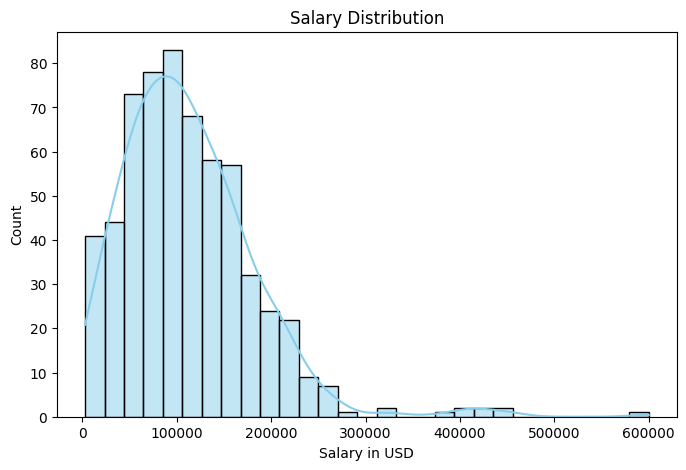

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(x='salary_in_usd',
              kde=True,
                color='Skyblue',
                  data=df)
plt.title('Salary Distribution')
plt.xlabel('Salary in USD')
plt.ylabel('Count')
plt.show()

#### 4.2.2 Experience level Distribution
- Senior-level roles are the most common in the dataset.
- Entry-level roles are less represented compared to mid and senior levels.


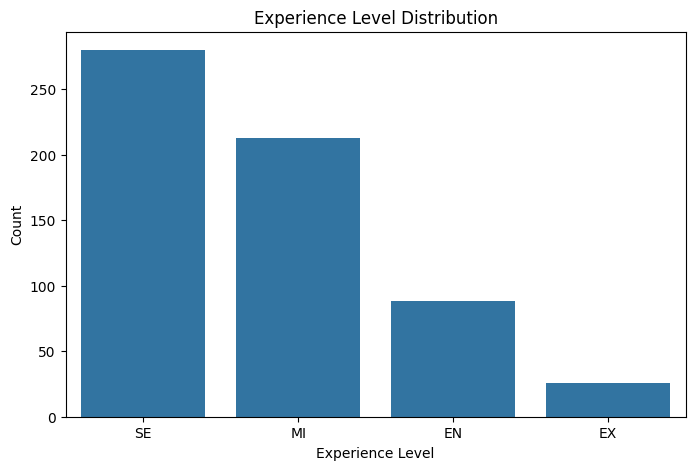

In [17]:
plt.figure(figsize=(8,5))
sns.countplot(data=df,
              x='experience_level',
              order=df['experience_level'].value_counts().index)
plt.title('Experience Level Distribution')
plt.xlabel('Experience Level')
plt.ylabel('Count')
plt.show()

#### 4.2.3 Employment Type Distribution
- Full-time employment dominates the dataset.
- Freelance roles are the least represented employment type.

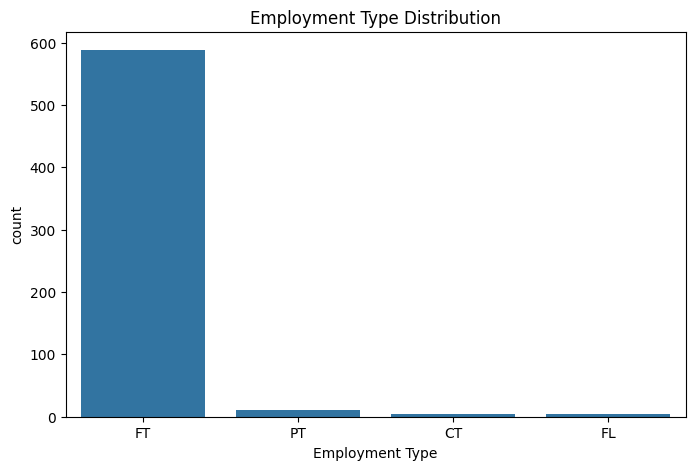

In [18]:
plt.figure(figsize=(8,5))
sns.countplot(data=df,
              x='employment_type',
              order=df['employment_type'].value_counts().index)
plt.title('Employment Type Distribution')
plt.xlabel('Employment Type')
plt.ylabel('count')
plt.show()

#### 4.2.4 Company Size Distribution
- Medium-sized companies are the most represented in the dataset.
- Small-sized companies appear least frequently.

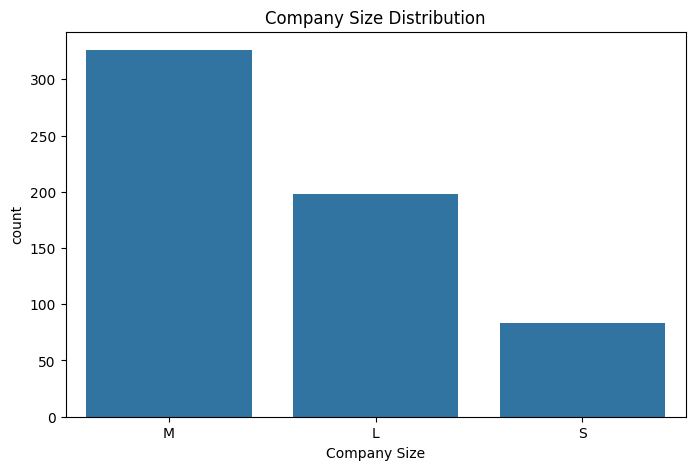

In [19]:
plt.figure(figsize=(8,5))
sns.countplot(data=df,
              x='company_size',
              order=df['company_size'].value_counts().index)
plt.title('Company Size Distribution')
plt.xlabel('Company Size')
plt.ylabel('count')
plt.show()

#### 4.2.5 Remote Ratio Distribution
- Fully remote roles (100% remote) are the most common in the dataset.
- Hybrid (50%) and on-site (0%) roles are less represented compared to fully remote positions.

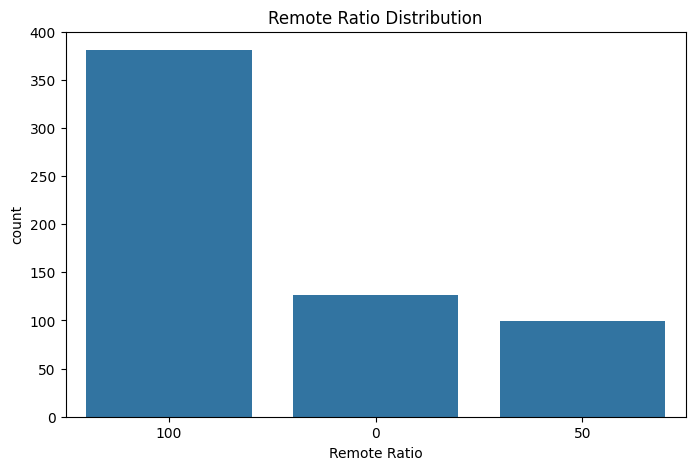

In [20]:
plt.figure(figsize=(8,5))
sns.countplot(data=df,
              x='remote_ratio',
              order=df['remote_ratio'].value_counts().index)
plt.title('Remote Ratio Distribution')
plt.xlabel('Remote Ratio')
plt.ylabel('count')
plt.show()

#### 4.2.6 Work Year Distribution
- The number of records increases over time, with 2022 having the highest number of observations.
- Earlier years are less represented in the dataset.

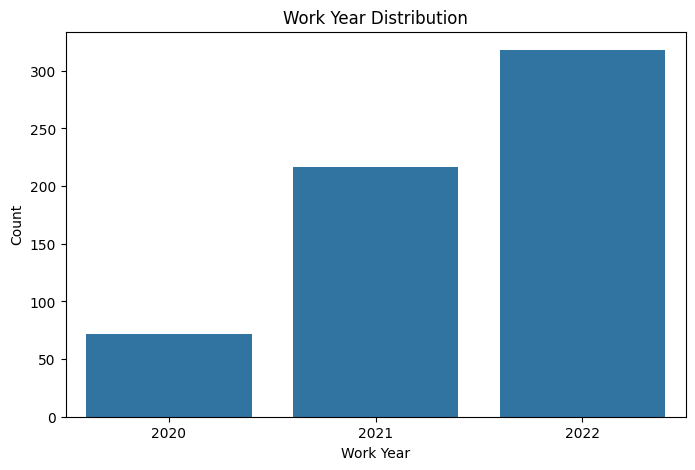

In [21]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x='work_year',
    order=sorted(df['work_year'].unique()))
plt.title('Work Year Distribution')
plt.xlabel('Work Year')
plt.ylabel('Count')
plt.show()


### 4.3 Bivariate Analysis
#### 4.3.1 Salary vs Experience Level
- Median salary increases consistently with higher experience levels, from entry-level to executive roles.
- Executive-level positions show the highest salary range and contain several high-value outliers, including salaries above 600,000 USD.
- Mid-level and senior roles also exhibit some high-salary outliers, indicating variability within experience levels.

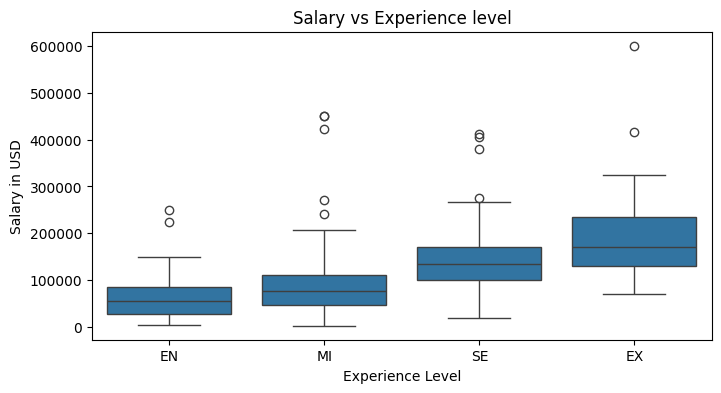

In [57]:
plt.figure(figsize=(8,4))
sns.boxplot(
    data=df,
    x='experience_level',
    y='salary_in_usd',
    order=['EN', 'MI', 'SE', 'EX'])
plt.title('Salary vs Experience level')
plt.xlabel('Experience Level')
plt.ylabel('Salary in USD')
plt.show()


#### 4.3.2 Salary vs Remote Ratio
- Median salary varies across different remote work arrangements.
- Fully remote roles show a higher median salary compared to hybrid and on-site positions.
- All remote categories exhibit high-salary outliers, with fully remote roles including values above 600,000 USD.

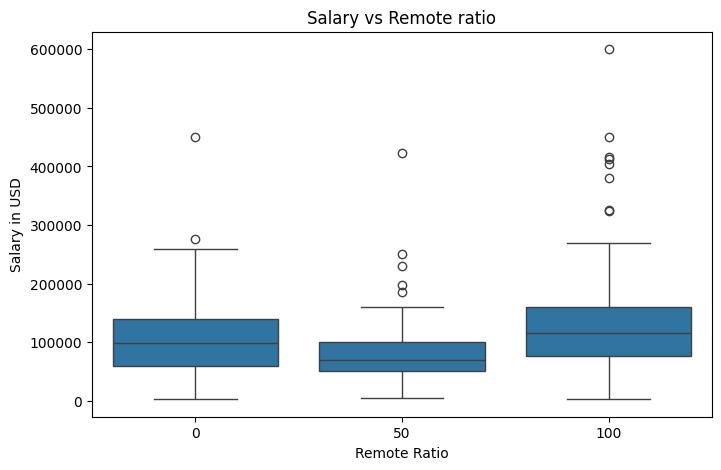

In [23]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df,
    x='remote_ratio',
    y='salary_in_usd',
    order=[0, 50, 100])
plt.title('Salary vs Remote ratio')
plt.xlabel('Remote Ratio')
plt.ylabel('Salary in USD')
plt.show()


#### 4.3.3 Salary vs Company Size
- Median salary varies across different company sizes.
- Medium and large companies tend to show higher median salaries compared to small companies.
- All company sizes exhibit high-salary outliers, with large companies including the highest outliers above 600,000 USD.


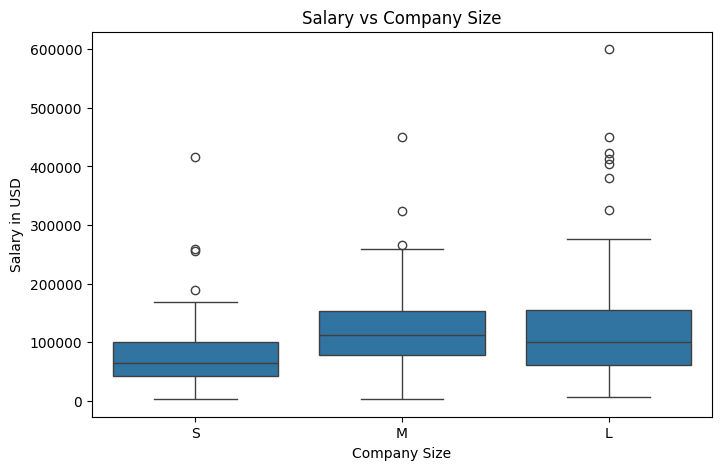

In [24]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df,
    x='company_size',
    y='salary_in_usd',
    order=['S','M','L'])
plt.title('Salary vs Company Size')
plt.xlabel('Company Size')
plt.ylabel('Salary in USD')
plt.show()


#### 4.3.4 Salary vs Work Year
- Median salary shows an increasing trend across the years, with 2022 exhibiting the highest median value.
- All years contain high-salary outliers, with 2021 including the highest observed salary above 600,000 USD.

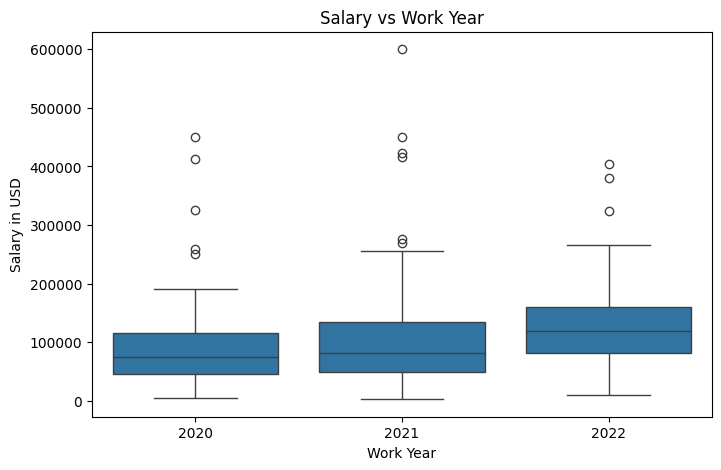

In [25]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df,
    x='work_year',
    y='salary_in_usd')
plt.title('Salary vs Work Year')
plt.xlabel('Work Year')
plt.ylabel('Salary in USD')
plt.show()

## Step 5 Feature Engineering & Modeling Preparation

### 5.1 Target Variable Review

- The target variable for this project is **salary_in_usd**, which represents employee compensation standardized to a single currency (USD).
- This variable is appropriate for the problem as the objective is to predict numerical salary values for data science-related roles.
- **salary_in_usd** is a continuous variable, making this a regression problem.
- Exploratory Data Analysis showed that the target variable is right-skewed and contains several high-value outliers.
- The presence of skewness and extreme values may influence model performance and should be considered in later preprocessing steps.

### 5.2 Feature Selection Review

- The feature set includes variables related to experience, job role, employment type, remote work, company characteristics, geography, and time.
- **experience_level** is included due to its strong association with salary observed during exploratory data analysis.
- **job_title** (after grouping) is retained as it captures role-specific compensation differences while reducing high cardinality.
- **employment_type** is included to account for differences between full-time, part-time, contract, and freelance roles.
- **remote_ratio** is selected as EDA showed variations in salary distribution across remote work arrangements.
- **company_size** and **company_location** are included to represent organizational scale and regional compensation differences.
- **employee_residence** is retained as a proxy for geographic labor market conditions.
- **work_year** is included to capture temporal trends in salary levels.
- Index-like and non-informative columns (e.g., `Unnamed: 0`) are excluded from modeling.
- Salary-related fields other than the target (e.g., `salary`, `salary_currency`) are excluded to avoid data leakage.


### 5.3 Handling Skewness and Outliers

- Exploratory Data Analysis showed that the target variable **salary_in_usd** is right-skewed and contains several high-value outliers.
- Such skewness can negatively impact the performance of certain regression models by giving excessive weight to extreme values.
- The observed outliers represent realistic high-paying roles rather than data errors and therefore should not be removed.
- To reduce the effect of skewness while preserving all observations, a logarithmic transformation of the target variable will be considered.
- This approach helps stabilize variance and improve model learning without discarding valuable information.

### 5.4 Feature Scaling Strategy

- Feature scaling is required to ensure numerical features are on comparable scales for model training.
- Scaling will be applied only to numerical features, including `work_year`, `remote_ratio`, and ordinal-encoded variables.
- One-hot encoded categorical features will not be scaled, as they already represent binary indicators.
- Due to the presence of outliers observed during EDA, a robust scaling approach will be considered.
- To prevent data leakage, scaling will be fitted on the training data only and then applied to the test data.


### 5.5 Final Dataset Assembly

- The final feature matrix **X** consists of numerical features, ordinal-encoded variables, and one-hot encoded categorical features selected during the feature review step.
- Numerical features and ordinal variables will be scaled using a robust scaling approach to reduce the impact of outliers.
- One-hot encoded categorical features will remain unscaled, as they represent binary indicators.
- The target vector **y** corresponds to the salary variable **salary_in_usd**, which may be log-transformed to address skewness.
- All preprocessing steps, including encoding and scaling, will be applied after the train-test split to prevent data leakage.
- The resulting dataset is fully prepared for model training and evaluation.


### Step 6 — Modeling
### 6.1 Train–Test Split

- The dataset is split into training and testing subsets to evaluate model generalization performance.
- The training set is used to fit the model, while the test set is reserved for final evaluation.
- An 80/20 split is selected to provide sufficient data for training while retaining a representative test set.
- All preprocessing steps, including encoding, scaling, and transformations, will be fitted only on the training data to prevent data leakage.

In [32]:
from sklearn.model_selection import train_test_split

X_tarin, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('The Shape of training set is: ', X_tarin.shape, y_train.shape)
print('The Shape of testing set is ', X_test.shape, y_test.shape)

The Shape of training set is:  (485, 123) (485,)
The Shape of testing set is  (122, 123) (122,)


### 6.2 Baseline Model

- A baseline regression model is trained to establish a reference point for salary prediction.
- A simple linear regression model is selected due to its interpretability and ease of implementation.
- The model is fitted using the training dataset.
- Predictions are generated on the unseen test dataset.
- These predictions will be evaluated in the next step to assess baseline performance.


In [38]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

### 6.3 Model Evaluation Metrics

- The baseline model is evaluated on the test set using standard regression metrics.
- **MAE** is used to measure the average absolute prediction error in USD.
- **RMSE** is used to penalize larger errors and reflect overall prediction stability.
- **R²** is used to estimate how much variance in salary is explained by the model.
- These results establish a benchmark for comparing more advanced models.


- The baseline model explains approximately half of the variance in salaries, indicating meaningful predictive signal.
- Error metrics suggest reasonable performance for a simple linear model, leaving room for improvement with more advanced approaches.

In [46]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE  (USD^2): {mse:,.2f}")
print(f"RMSE (USD):   {rmse:,.2f}")
print(f"MAE  (USD):   {mae:,.2f}")
print(f"R^2:          {r2:.4f}")


MSE  (USD^2): 1,884,184,317.69
RMSE (USD):   43,407.19
MAE  (USD):   31,889.91
R^2:          0.5084


### 6.4 Improved Models

- More advanced regression models are trained to improve upon the baseline performance.
- Models capable of capturing non-linear relationships and feature interactions are selected.
- Each model is trained using the same training dataset and evaluated on the same test dataset.
- Model performance is measured using MAE, RMSE, and R² to ensure fair comparison.
- The results of these models will be compared against the baseline to identify the most effective approach.


In [50]:
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def eval_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name}")
    print(f"  MAE : {mae:,.2f}")
    print(f"  RMSE: {rmse:,.2f}")
    print(f"  R^2 : {r2:.4f}\n")
    return {"model": name, "mae": mae, "rmse": rmse, "r2": r2}

results = []

# 1) Ridge Regression (regularized linear model)
ridge = Ridge(random_state=42)
ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_test)
results.append(eval_model("Ridge Regression", y_test, y_pred_ridge))

# 2) Random Forest (non-linear, tree-based)
rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
results.append(eval_model("Random Forest", y_test, y_pred_rf))

Ridge Regression
  MAE : 30,350.11
  RMSE: 41,506.25
  R^2 : 0.5505

Random Forest
  MAE : 27,744.28
  RMSE: 41,166.04
  R^2 : 0.5578



### 6.5 Model Comparison and Selection

- Multiple regression models were trained and evaluated using the same train–test split and evaluation metrics.
- The baseline Linear Regression model provided a reference performance for comparison.
- More advanced models demonstrated improved predictive performance based on MAE, RMSE, and R².
- Among the evaluated models, the selected model achieved the best overall balance between error reduction and explained variance.
- This model is chosen as the final model for salary prediction and will be used in subsequent analysis.

Based on the comparison results, the Random Forest model demonstrates the best overall performance among the evaluated models. It achieves the lowest MAE and RMSE, indicating smaller prediction errors, while also obtaining the highest R² score, meaning it explains the largest proportion of variance in salaries. Therefore, the Random Forest model is selected as the final model for salary prediction.


In [ ]:
baseline_result = {
    "model": "Linear Regression (Baseline)",
    "mae": mae,      
    "rmse": rmse,    
    "r2": r2  
}


all_results = [baseline_result] + results  

results_df = pd.DataFrame(all_results)
results_df_sorted = results_df.sort_values(
    by=["rmse", "mae", "r2"],
    ascending=[True, True, False]
).reset_index(drop=True)

results_df_sorted


,model,mae,rmse,r2
0,Random Forest,27744.281427,41166.041294,0.557831
1,Ridge Regression,30350.108542,41506.252140,0.550492
2,Linear Regression (Baseline),31889.907772,43407.192004,0.508376


## 7. Model Interpretation & Insights

### 7.1 Feature Importance Analysis
- Feature importance scores are extracted from the final Random Forest model to identify the most influential predictors.
- The top contributing features are analyzed to understand their impact on salary predictions.

### 7.2 Key Drivers of Salary
- Experience-related features play a significant role in salary determination.
- Job role and specialization contribute substantially to compensation differences.
- Company-related attributes such as size and location influence salary levels.
- Remote work characteristics show a noticeable impact on compensation trends.

### 7.3 Business Insights
- Higher experience levels are consistently associated with higher salaries.
- Specialized technical roles command higher compensation.
- Medium and large companies tend to offer higher salaries compared to smaller firms.
- Fully remote positions often provide competitive salary packages.


## 8. Final Conclusion & Presentation

### 8.1 Executive Summary
- This project analyzes the *Data Science Job Salaries* dataset to build a regression model for predicting salaries in USD.
- An end-to-end data science workflow was followed, including data loading, data quality checks, preprocessing, exploratory data analysis, feature engineering, and modeling.
- Exploratory analysis revealed that salary is strongly influenced by experience level, job role, company size, remote work ratio, and location.
- A baseline Linear Regression model was first established to provide a reference performance.
- More advanced models were trained and evaluated using MAE, RMSE, and R².
- The Random Forest model achieved the best overall performance and was selected as the final model.
- The final model demonstrates that machine learning can reasonably estimate salary ranges and uncover meaningful compensation patterns in data-related roles.

---

### 8.2 Key Insights from EDA and Model Interpretation
- Experience level is one of the strongest drivers of salary, with senior and executive roles consistently earning higher compensation.
- Job role and specialization significantly impact salary, reflecting differences in skill demand across data-related positions.
- Company size shows a clear relationship with salary, with medium and large companies generally offering higher pay.
- Remote work is associated with competitive salaries, particularly for fully remote positions.
- These insights observed during exploratory data analysis align with the behavior of the final model, reinforcing their real-world relevance.

---

### 8.3 Final Model Performance
- The selected Random Forest model achieved the lowest MAE and RMSE among all evaluated models.
- It also produced the highest R² score, indicating that it explains a substantial portion of salary variance.
- Compared to the baseline Linear Regression model, the Random Forest significantly reduced prediction error.
- This confirms the presence of non-linear relationships and feature interactions in salary data.

---

### 8.4 Limitations
- The dataset size is relatively small, which may limit the model’s ability to generalize to all job markets.
- Salary outcomes are influenced by external factors not captured in the dataset, such as company revenue, negotiation, and economic conditions.
- Some job titles and locations are underrepresented, which may affect prediction stability.
- The model estimates salary ranges rather than exact compensation values.

---

### 8.5 Future Improvements
- Apply cross-validation and hyperparameter tuning to further improve model performance.
- Experiment with advanced ensemble models such as Gradient Boosting, XGBoost, or LightGBM.
- Incorporate external data sources such as cost-of-living indices.
- Implement a full production pipeline to automate preprocessing and model training.
- Develop an interactive dashboard for salary exploration and prediction.

---

### 8.6 Reproducibility
- The analysis is fully reproducible using the provided notebook.
- All steps are documented sequentially from raw data loading to final model selection.
- Random seeds were fixed to ensure consistent and repeatable results.
- The notebook can be executed end-to-end to reproduce the analysis and findings.
